<a href="https://colab.research.google.com/github/Deeksha2807/AI_COE/blob/main/ANN_Moons_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (1000, 2)


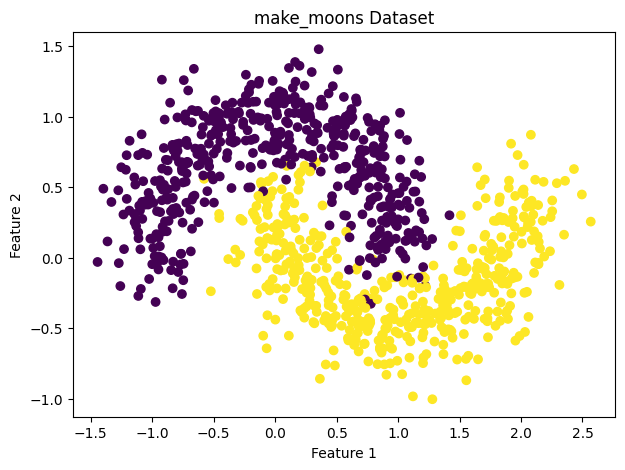

Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.5672 - loss: 0.6255 - val_accuracy: 0.7000 - val_loss: 0.5632
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7063 - loss: 0.5742 - val_accuracy: 0.8188 - val_loss: 0.5061
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7625 - loss: 0.5255 - val_accuracy: 0.8625 - val_loss: 0.4502
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7891 - loss: 0.4788 - val_accuracy: 0.8625 - val_loss: 0.3987
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8000 - loss: 0.4386 - val_accuracy: 0.8875 - val_loss: 0.3531
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8141 - loss: 0.4044 - val_accuracy: 0.8938 - val_loss: 0.3167
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8234 - loss: 0.3787 - val_accuracy: 0.9000 - val_loss: 0.2895
Epoch 8/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8266 - loss: 0.3611 - val_accuracy: 0.

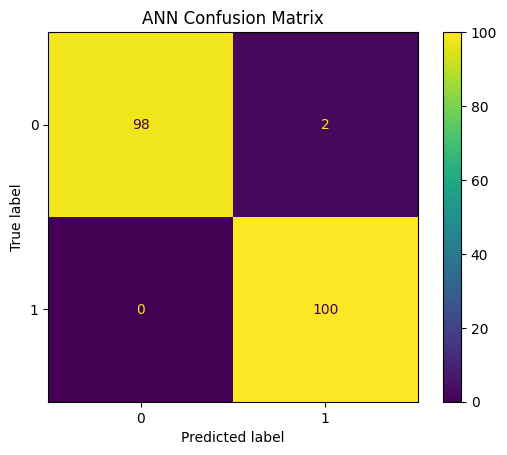

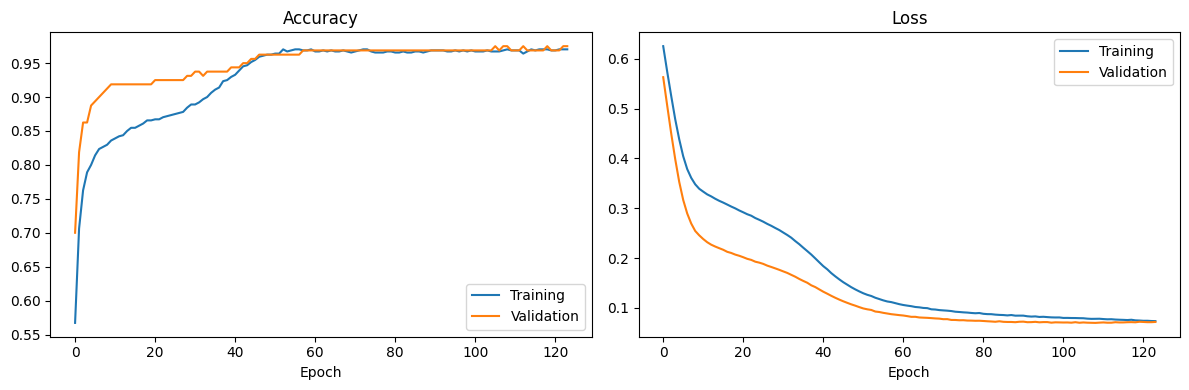

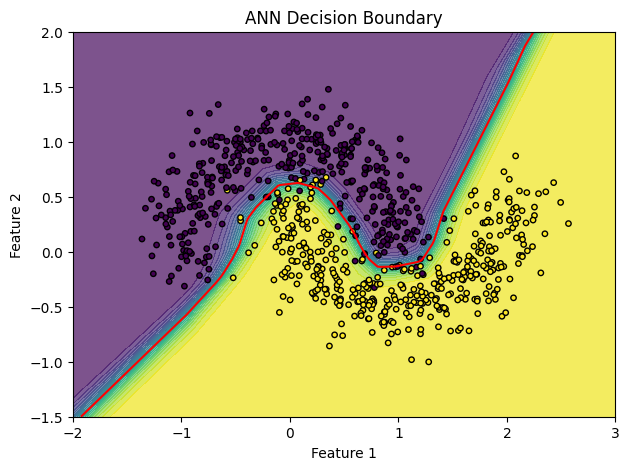


Project completed successfully!


In [1]:

# ANN Binary Classification using make_moons

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# 1. Generate dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

print("Dataset shape:", X.shape)

# 2. Display dataset
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis")
plt.title("make_moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("dataset.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Build ANN
model = Sequential([
    Input(shape=(2,)),
    Dense(16, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

# 6. Compile
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 7. Train
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 8. Evaluate
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("ANN Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 10. Training graphs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.savefig("training_graphs.png", dpi=150, bbox_inches="tight")
plt.show()

# 11. Decision boundary
xx, yy = np.meshgrid(
    np.linspace(-2, 3, 300),
    np.linspace(-1.5, 2, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
Z = model.predict(grid_scaled, verbose=0).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, levels=20, cmap="viridis", alpha=0.7)
plt.contour(xx, yy, Z, levels=[0.5], colors="red")
plt.scatter(
    scaler.inverse_transform(X_train)[:, 0],
    scaler.inverse_transform(X_train)[:, 1],
    c=y_train, edgecolors="black", s=15
)
plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nProject completed successfully!")
